# Model 5: CNN Trained from Scratch
Dataset:** Plant Disease Recognition (Healthy / Powdery / Rust)

**Category:** Deep Learning

## Model suitability
A CNN learns spatial features (edges, spots, textures) directly from the 2D image, which is what separates rust and
powdery mildew from healthy leaves. Unlike SVM or Random Forest it does not need hand-made features.

## Implementation details
TensorFlow/Keras `Sequential` model: 3 Conv2D blocks (32→64→128 filters, 3×3, ReLU) with max-pooling, then Flatten,
Dense(128) and a softmax output. Adam optimiser, `sparse_categorical_crossentropy`, images 128×128.
Training data is augmented (rotation, shifts, flip, zoom) in V1 to V3. Validation and Test data are only rescaled.

## Parameter tuning method
Manual: baseline (V1) vs Dropout(0.5) (V2) vs Dropout(0.5) + BatchNormalization (V3).
A pre-processing variety (V4) trains the same baseline without data augmentation.

## Evaluation metric & validation method
Accuracy for train/validation/test, learning curves to detect overfitting, and a confusion matrix with per-class
precision/recall/F1 on the Test set. The dataset's own **Validation** folder is used during training, and the
**Test** folder is used once at the end.

> **Running locally:** this notebook uses TensorFlow. ~1,300 images at 128×128 train fine on CPU.
> On native Windows, TensorFlow 2.11+ does not use the GPU, so use WSL2 or Colab if you want GPU speed-up.

In [2]:
# ---- Configuration (paths are relative to the notebooks/ folder) ----
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
warnings.filterwarnings('ignore')

DATA_ROOT = '../data/raw'      # folder that contains Train/, Validation/ and Test/
SPLITS = {s: os.path.join(DATA_ROOT, s, s) for s in ['Train', 'Validation', 'Test']}  # dataset is nested: Train/Train/...
RESULTS = '../results'
os.makedirs(f'{RESULTS}/eda_visualizations', exist_ok=True)
os.makedirs(f'{RESULTS}/outputs', exist_ok=True)

CLASS_NAMES = sorted(d for d in os.listdir(SPLITS['Train']) if os.path.isdir(os.path.join(SPLITS['Train'], d)))
print('Classes:', CLASS_NAMES)
for s, p in SPLITS.items():
    print(s, {c: len(os.listdir(os.path.join(p, c))) for c in CLASS_NAMES})

Classes: ['Healthy', 'Powdery', 'Rust']
Train {'Healthy': 458, 'Powdery': 430, 'Rust': 434}
Validation {'Healthy': 20, 'Powdery': 20, 'Rust': 20}
Test {'Healthy': 50, 'Powdery': 50, 'Rust': 50}


In [3]:
# Helper: every notebook appends its results to one shared CSV (used later for the group comparison)
def log_result(model, variety, val_acc=None, test_acc=None, notes=''):
    path = f'{RESULTS}/outputs/model_results.csv'
    cols = ['model', 'variety', 'val_accuracy', 'test_accuracy', 'notes']
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=cols)
    df = df[~((df['model'] == model) & (df['variety'] == variety))].reset_index(drop=True)
    df.loc[len(df)] = [model, variety, val_acc, test_acc, notes]
    df.to_csv(path, index=False)

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

tf.keras.utils.set_random_seed(42)
IMG_SIZE, BATCH = 128, 32

def show_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(title); plt.tight_layout()
    plt.savefig(f'{RESULTS}/eda_visualizations/{fname}', dpi=200); plt.show()

def plot_curves(histories, fname):
    fig, ax = plt.subplots(1, len(histories), figsize=(5 * len(histories), 3.5), squeeze=False)
    for a, (name, h) in zip(ax[0], histories.items()):
        a.plot(h.history['accuracy'], label='train'); a.plot(h.history['val_accuracy'], label='validation')
        a.set_title(name, fontsize=9); a.set_xlabel('epoch'); a.set_ylabel('accuracy'); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f'{RESULTS}/eda_visualizations/{fname}', dpi=200); plt.show()

In [5]:
EPOCHS = 15

train_aug = ImageDataGenerator(rescale=1 / 255., rotation_range=20, width_shift_range=0.2,
                               height_shift_range=0.2, horizontal_flip=True, zoom_range=0.2, fill_mode='nearest')
plain = ImageDataGenerator(rescale=1 / 255.)

def flow(gen, split, shuffle):
    return gen.flow_from_directory(SPLITS[split], target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
                                   class_mode='sparse', classes=CLASS_NAMES, shuffle=shuffle)

train_gen = flow(train_aug, 'Train', True)
val_gen = flow(plain, 'Validation', False)
test_gen = flow(plain, 'Test', False)
print(train_gen.class_indices)

Found 1322 images belonging to 3 classes.
Found 60 images belonging to 3 classes.
Found 150 images belonging to 3 classes.
{'Healthy': 0, 'Powdery': 1, 'Rust': 2}


In [6]:
def build_cnn(dropout=0.0, batchnorm=False, lr=1e-3):
    m = models.Sequential([layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))])
    for f in [32, 64, 128]:
        m.add(layers.Conv2D(f, 3, activation='relu'))
        if batchnorm:
            m.add(layers.BatchNormalization())
        m.add(layers.MaxPooling2D(2))
    m.add(layers.Flatten())
    if dropout:
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(128, activation='relu'))
    m.add(layers.Dense(len(CLASS_NAMES), activation='softmax'))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

build_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
from sklearn.metrics import f1_score

configs = {'V1 baseline': dict(),
           'V2 Dropout 0.5': dict(dropout=0.5),
           'V3 Dropout 0.5 + BatchNorm': dict(dropout=0.5, batchnorm=True)}
trained, histories, rows = {}, {}, []
for name, cfg in configs.items():
    print('\n=== Training', name, '===')
    m = build_cnn(**cfg)
    h = m.fit(train_gen, validation_data=val_gen, epochs=EPOCHS, verbose=2)
    _, val_acc = m.evaluate(val_gen, verbose=0)
    _, test_acc = m.evaluate(test_gen, verbose=0)
    y_pred = np.argmax(m.predict(test_gen, verbose=0), axis=1)
    test_f1 = f1_score(test_gen.classes, y_pred, average='macro')
    rows.append([name, h.history['accuracy'][-1], val_acc, test_acc,
                 h.history['accuracy'][-1] - val_acc, test_f1])
    trained[name], histories[name] = m, h
comparison = pd.DataFrame(rows, columns=['Variety', 'Train acc', 'Val acc', 'Test acc',
                                         'Train-Val gap', 'Test macro-F1']).round(3)
comparison


=== Training V1 baseline ===
Epoch 1/15
42/42 - 96s - 2s/step - accuracy: 0.4508 - loss: 1.0775 - val_accuracy: 0.3167 - val_loss: 1.5550
Epoch 2/15
42/42 - 95s - 2s/step - accuracy: 0.6036 - loss: 0.8172 - val_accuracy: 0.6333 - val_loss: 0.7531
Epoch 3/15
42/42 - 99s - 2s/step - accuracy: 0.6762 - loss: 0.6817 - val_accuracy: 0.6833 - val_loss: 0.7225
Epoch 4/15
42/42 - 98s - 2s/step - accuracy: 0.7806 - loss: 0.5481 - val_accuracy: 0.7833 - val_loss: 0.5350
Epoch 5/15
42/42 - 110s - 3s/step - accuracy: 0.8275 - loss: 0.4770 - val_accuracy: 0.8333 - val_loss: 0.4587
Epoch 6/15
42/42 - 102s - 2s/step - accuracy: 0.8752 - loss: 0.3537 - val_accuracy: 0.8667 - val_loss: 0.3271
Epoch 7/15
42/42 - 96s - 2s/step - accuracy: 0.8707 - loss: 0.3618 - val_accuracy: 0.9000 - val_loss: 0.3173
Epoch 8/15
42/42 - 99s - 2s/step - accuracy: 0.8828 - loss: 0.2972 - val_accuracy: 0.8500 - val_loss: 0.3681
Epoch 9/15
42/42 - 97s - 2s/step - accuracy: 0.8865 - loss: 0.3060 - val_accuracy: 0.8833 - val_

,Variety,Train acc,Val acc,Test acc,Train-Val gap,Test macro-F1
0,V1 baseline,0.932,0.900,0.947,0.032,0.947
1,V2 Dropout 0.5,0.940,0.933,0.947,0.007,0.947
2,V3 Dropout 0.5 + BatchNorm,0.939,0.767,0.800,0.173,0.802


In [8]:
# V4: same architecture as V1, but NO data augmentation (pre-processing variety)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import f1_score

noaug = ImageDataGenerator(rescale=1/255.)          # only rescaling, no rotation/shift/flip/zoom
train_gen_noaug = noaug.flow_from_directory(
    SPLITS['Train'], target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    class_mode='sparse', classes=CLASS_NAMES, shuffle=True)

name = 'V4 baseline, no augmentation'
m = build_cnn()                                      # same settings as V1
h = m.fit(train_gen_noaug, validation_data=val_gen, epochs=EPOCHS, verbose=2)

_, val_acc = m.evaluate(val_gen, verbose=0)
_, test_acc = m.evaluate(test_gen, verbose=0)
y_pred = np.argmax(m.predict(test_gen, verbose=0), axis=1)
test_f1 = f1_score(test_gen.classes, y_pred, average='macro')
train_acc = h.history['accuracy'][-1]

trained[name], histories[name] = m, h
comparison.loc[len(comparison)] = [name, train_acc, val_acc, test_acc, train_acc - val_acc, test_f1]
comparison = comparison.round(3)
comparison

Found 1322 images belonging to 3 classes.
Epoch 1/15
42/42 - 79s - 2s/step - accuracy: 0.5492 - loss: 0.8999 - val_accuracy: 0.6500 - val_loss: 0.6620
Epoch 2/15
42/42 - 75s - 2s/step - accuracy: 0.7761 - loss: 0.5436 - val_accuracy: 0.7333 - val_loss: 0.4955
Epoch 3/15
42/42 - 74s - 2s/step - accuracy: 0.9024 - loss: 0.2816 - val_accuracy: 0.8333 - val_loss: 0.3873
Epoch 4/15
42/42 - 73s - 2s/step - accuracy: 0.9281 - loss: 0.2208 - val_accuracy: 0.8500 - val_loss: 0.3029
Epoch 5/15
42/42 - 85s - 2s/step - accuracy: 0.9455 - loss: 0.1675 - val_accuracy: 0.8667 - val_loss: 0.2928
Epoch 6/15
42/42 - 81s - 2s/step - accuracy: 0.9508 - loss: 0.1409 - val_accuracy: 0.9167 - val_loss: 0.3260
Epoch 7/15
42/42 - 74s - 2s/step - accuracy: 0.9592 - loss: 0.1409 - val_accuracy: 0.9000 - val_loss: 0.2841
Epoch 8/15
42/42 - 77s - 2s/step - accuracy: 0.9720 - loss: 0.0785 - val_accuracy: 0.9167 - val_loss: 0.3044
Epoch 9/15
42/42 - 73s - 2s/step - accuracy: 0.9758 - loss: 0.0761 - val_accuracy: 0.9

,Variety,Train acc,Val acc,Test acc,Train-Val gap,Test macro-F1
0,V1 baseline,0.932,0.900,0.947,0.032,0.947
1,V2 Dropout 0.5,0.940,0.933,0.947,0.007,0.947
2,V3 Dropout 0.5 + BatchNorm,0.939,0.767,0.800,0.173,0.802
3,"V4 baseline, no augmentation",0.998,0.950,0.947,0.048,0.947


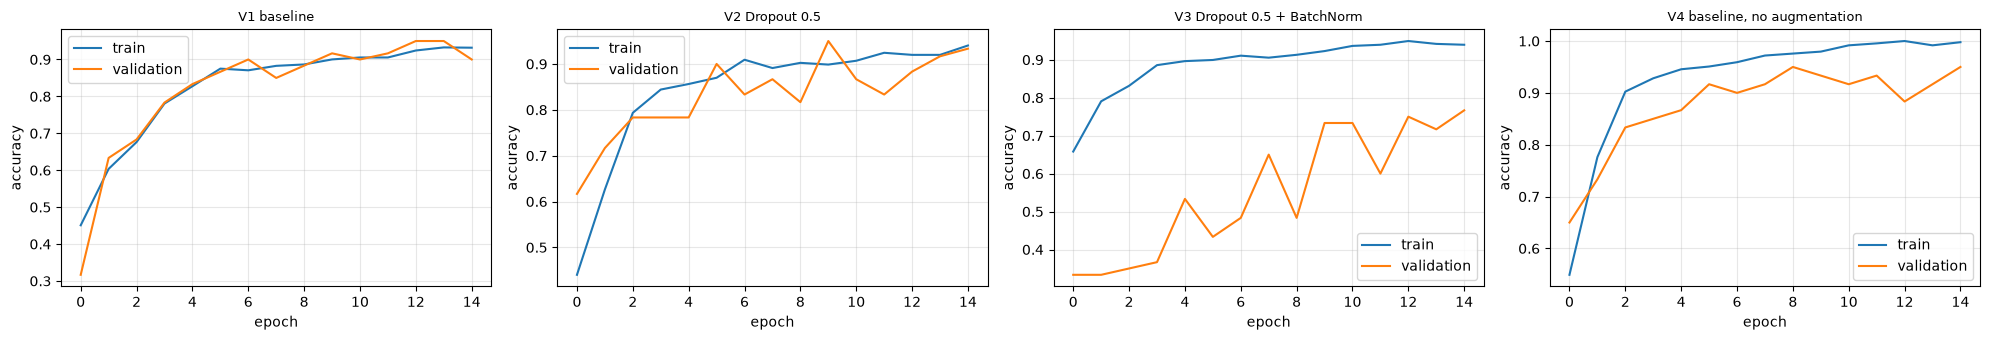

In [11]:
plot_curves(histories, 'cnn_scratch_curves.png')

## Comparison across varieties
Compare the four rows. Does Dropout shrink the train–validation gap? Did BatchNorm help? Does removing data augmentation (V4) change the result? Look at the learning curves for overfitting.
Note: the validation set is small (about 60 images), so compare it together with the curves and Test accuracy.

Selected: V4 baseline, no augmentation
              precision    recall  f1-score   support

     Healthy       0.89      0.98      0.93        50
     Powdery       0.98      0.90      0.94        50
        Rust       0.98      0.96      0.97        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150



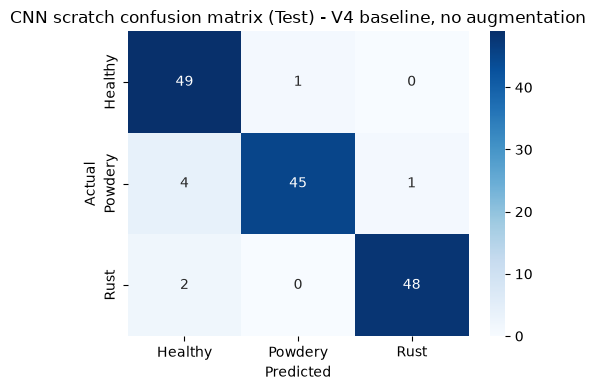

In [10]:
# Select by validation accuracy, then report Test results with a confusion matrix
best_name = comparison.sort_values('Val acc', ascending=False).iloc[0]['Variety']
best = trained[best_name]
print('Selected:', best_name)
y_pred = np.argmax(best.predict(test_gen, verbose=0), axis=1)
print(classification_report(test_gen.classes, y_pred, target_names=CLASS_NAMES))
show_confusion(test_gen.classes, y_pred, f'CNN scratch confusion matrix (Test) - {best_name}', 'cnn_scratch_confusion_matrix.png')

best.save(f'{RESULTS}/outputs/cnn_scratch.keras')
for _, r in comparison.iterrows():
    log_result('CNN (scratch)', r['Variety'], r['Val acc'], r['Test acc'], f"train={r['Train acc']}")

## Conclusion

* **Core Achievement:** Model 5 implements and evaluates a custom Convolutional Neural Network (CNN) trained from scratch to classify plant leaves into three categories: Healthy, Powdery, and Rust.
* **Overall Performance:** The V1 baseline, V2 (Dropout 0.5) and V4 (no augmentation) all reached the same **94.7% test accuracy and 0.947 macro-F1**. This shows that a simple 3-block CNN is enough for this dataset.
* **Model Selection:** Selection was done on validation accuracy, and **V4 (baseline without data augmentation)** had the highest value (**0.950**), so it was selected as the final model. Its per-class F1 scores on the Test set were 0.93 (Healthy), 0.94 (Powdery) and 0.97 (Rust). Because V1, V2 and V4 have identical test accuracy and the validation set is small (60 images), the differences between them are not strong.
* **Regularization Analysis:** Dropout alone (V2) did not reduce test accuracy and gave the smallest train-validation gap (**0.007**). Adding BatchNormalization on top (V3) clearly hurt, dropping to **80.0% test accuracy** with a large gap of **0.173**. Its validation accuracy was also unstable across epochs.
* **Effect of Data Augmentation:** Removing augmentation (V4) raised training accuracy to about **99.8%** while test accuracy stayed at 94.7%, so the train-validation gap grew from 0.032 (V1) to 0.048. Augmentation therefore helps reduce overfitting, but on this dataset it did not improve test accuracy.
* **Final Takeaway:** For this dataset, a simple CNN with or without Dropout works best, while Dropout combined with BatchNormalization is not recommended with these settings. Future work could try tuning the learning rate, using a milder Dropout value, or using transfer learning.

## Limitations & Observations

* **Small Validation and Test Sets:** The Validation set has only 60 images and the Test set 150, so a single misclassified image changes accuracy by about 0.7 to 1.7%. Small differences between variants should not be over-interpreted.
* **Unstable V3:** The Dropout + BatchNorm model showed large swings in validation accuracy and loss between epochs, which suggests that BatchNorm combined with Dropout is sensitive on such a small dataset.
* **Run-to-Run Variation:** Neural network training is random, so exact numbers can change slightly when the notebook is re-run, even with a fixed seed. Results were checked together with the learning curves rather than relying on one number.
* **Overfitting Without Augmentation:** V4 reached almost 100% training accuracy, showing that the model memorises the training images when augmentation is removed.
* **Dataset Scope:** The evaluation covers only three classes (Healthy, Powdery, Rust) from one dataset, so the results may not carry over to other plant diseases or different image conditions.